# Imports

In [384]:
import numpy as np
import matplotlib.pyplot as plt
import json
from numba import njit
from scipy.signal import envelope

# Import parameters

In [385]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

def calculate_variables(params):
    array_length = params["array"]["length"] #transducer array length
    frequency = params["wave"]["frequency"] #hz
    c = params["wave"]["c"] #speed of sound in m/s
    sampling_rate = params["wave"]["sampling_rate"] #1/s = 16 * frequency
    total_depth = params["simulation"]["total_depth"] #total depth in m
    pitch = params["array"]["pitch"] #pitch in m
    
    step_size = 1 / sampling_rate #cuz frequency = 1 / T 
    samples = int(sampling_rate * (total_depth / c)) #sampling rate 1/s * total depth m / (m/s) = samples - samples needed to cover the total depth
    total_depth_sample = (total_depth / 2) / samples #total depth in m / number of samples = depth per sample
    
    pos = np.linspace(start=0, stop=array_length, num=array_length, dtype=int) #array position sampling
    time = np.linspace(start=0, stop=step_size * samples, num=samples) #time sampling
    
    params["simulation"]["step_size"] = step_size #step size in s
    params["simulation"]["samples"] = samples 
    params["simulation"]["total_depth_sample"] = total_depth_sample #depth per sample in m
    params["simulation"]["maximal_acquisition_depth"] = c * (step_size * samples) / 2 #maximal acquisition depth in m
    params["simulation"]["lateral_step"] = (array_length * pitch) * (1 / params['simulation']['lateral_resolution'])
    
    print("Aperture: ", params["array"]["aperture"])
    print("Samples: ", samples)
    print("Total depth samples: ", total_depth_sample)
    print("Step size: ", step_size, "s")
    print("Maximal acquisition depth:", params["simulation"]["maximal_acquisition_depth"], "m")
    print("Lateral step: ", params["simulation"]["lateral_step"], "m")
    
    return params, pos, time

In [386]:
parameters = load_parameters("./parameters.json")
params, pos, time = calculate_variables(parameters)

Aperture:  0.8
Samples:  3200
Total depth samples:  3.125e-06
Step size:  4.166666666666667e-09 s
Maximal acquisition depth: 0.01 m
Lateral step:  1.25e-05 m


## Objects

In [387]:
class Objects:
    def __init__(self, depth, position):
        self.depth = depth
        self.position = position
        self.delays = np.zeros(params["array"]["length"])
        self.rf_matrix = np.zeros((params["simulation"]["samples"], params["array"]["length"]))
        self.rf_matrix_zm = np.zeros((params["simulation"]["samples"], params["array"]["length"]))
        self.rf_matrix_dc1 = np.zeros((params["simulation"]["samples"], params["array"]["length"]))
        self.rf_matrix_dc2 = np.zeros((params["simulation"]["samples"], params["array"]["length"]))
        self.effective_array_length = 0
        self.effective_angle = 0

In [388]:
objects = [
            Objects(params["objects"][0]["depth"], params["objects"][0]["position"]),
            Objects(params["objects"][1]["depth"], params["objects"][1]["position"]),
            Objects(params["objects"][2]["depth"], params["objects"][2]["position"]),
            Objects(params["objects"][3]["depth"], params["objects"][3]["position"]) 
            ]

In [389]:
def find_object_effective_aperture(objects, aperture):
    for i in range(0, len(objects)):
        objects[i].effective_array_length =  objects[i].depth / aperture
        print(f"Object {i+1} effective array length: {objects[i].effective_array_length} m") 

find_object_effective_aperture(objects, params["array"]["aperture"])

Object 1 effective array length: 0.00375 m
Object 2 effective array length: 0.005 m
Object 3 effective array length: 0.0038749999999999995 m
Object 4 effective array length: 0.011249999999999998 m


# NSI

## Import delays

In [390]:
def import_delay_data(objects, file="./data/csv/delays/delay_matrix_object"):
    for i in range(len(objects)):
        objects[i].delays = np.genfromtxt(f"{file}{i+1}.csv", delimiter=",")


In [391]:
import_delay_data(objects)

### Display delays

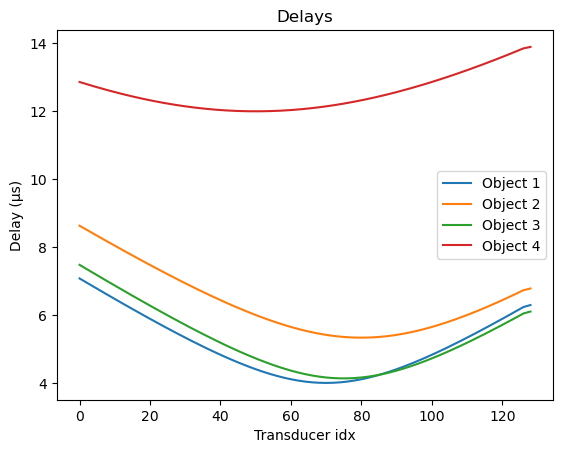

In [392]:
plt.figure()    
for i in range(0, len(objects)):
    plt.plot(pos, objects[i].delays*1e6, label = f"Object {i+1}")
plt.title("Delays")
plt.xlabel("Transducer idx")
plt.ylabel("Delay (µs)")
plt.legend()
plt.show()

## Import RF matrices

In [393]:
def import_RF_data(objects, file="./data/csv/rf_data/rf_matrix_object"):
    for i in range(len(objects)):
        objects[i].rf_matrix = np.genfromtxt(f"{file}{i+1}.csv", delimiter=',').reshape(params["simulation"]["samples"], params["array"]["length"])
        objects[i].rf_matrix_zm = objects[i].rf_matrix.copy()
        objects[i].rf_matrix_dc1 = objects[i].rf_matrix.copy()
        objects[i].rf_matrix_dc2 = objects[i].rf_matrix.copy()

In [394]:
import_RF_data(objects)

### Display RF data

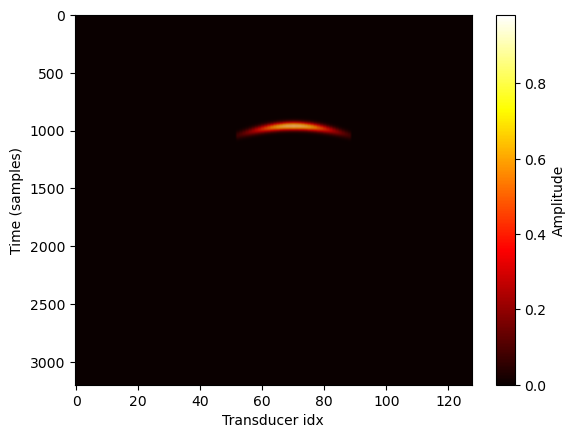

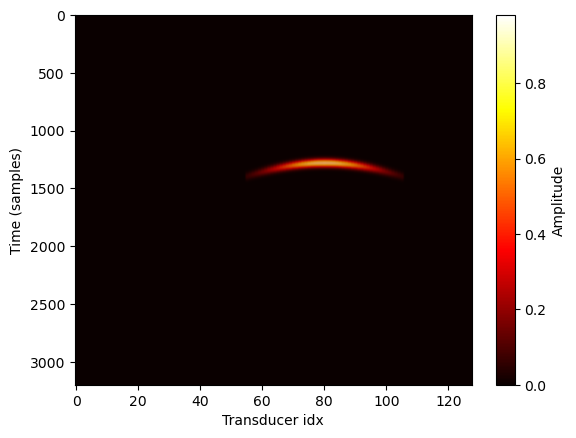

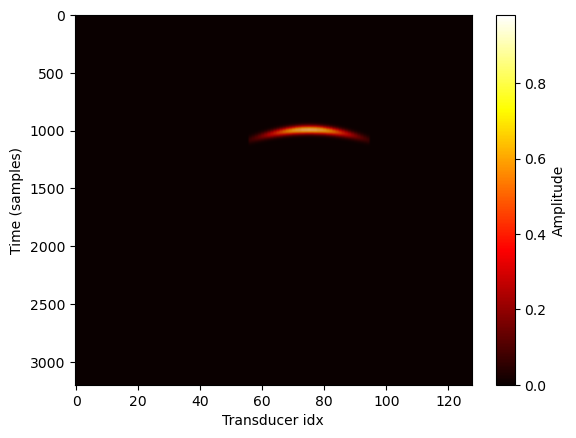

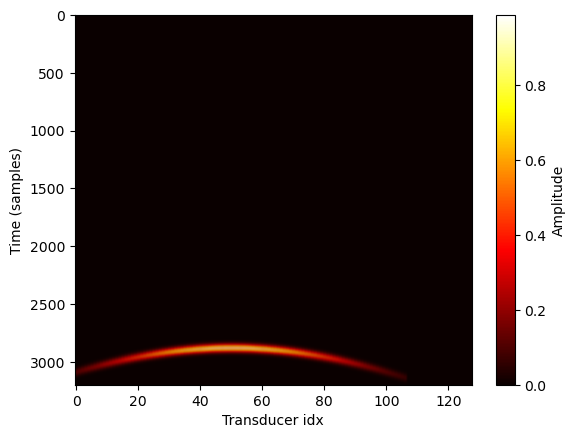

In [395]:
for i in range(0, len(objects)):
    objects[i].rf_matrix.tofile(f"./data/csv/rf_matrix_object{i+1}.csv", sep=",")
    plt.figure()
    plt.imshow(abs(objects[i].rf_matrix), cmap='hot', aspect='auto')
    plt.xlabel("Transducer idx")
    plt.ylabel("Time (samples)")
    plt.savefig(f"./data/images/rf_matrix_object{i+1}.png")
    plt.colorbar(label="Amplitude")
    plt.show()

## Apodization function

In [396]:
def generate_apodization(array_length, index, offset=0, mirror=False):
    if index >= 0 and index < array_length / 2:
        if mirror:
            return -1 + offset
        else:
            return 1 + offset
    elif index>=array_length/2 and index < array_length:
        if mirror:
            return 1 + offset
        else:
            return -1 + offset

C:\Users\Acer\AppData\Local\Temp\ipykernel_10096\1022317796.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


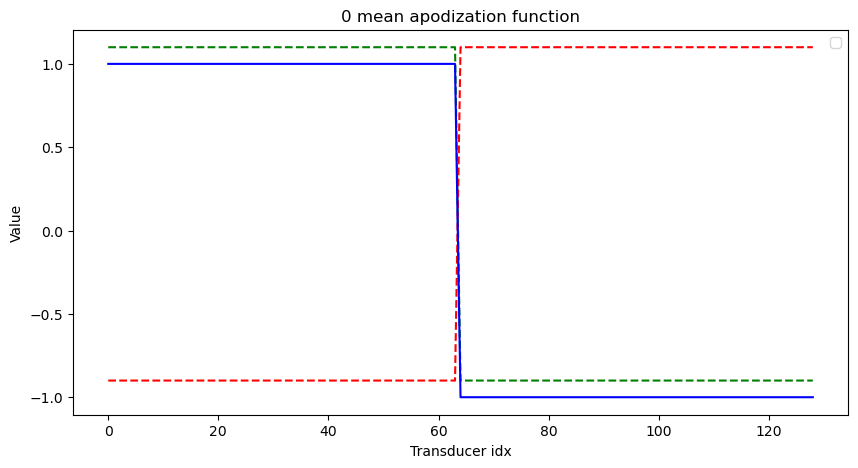

In [397]:
apodization_zm = np.array([generate_apodization(params["array"]["length"], i, offset=0, mirror=False) for i in range(params["array"]["length"])])
apodization_dc1 = np.array([generate_apodization(params["array"]["length"], i, offset=0.1, mirror=False) for i in range(params["array"]["length"])])
apodization_dc2 = np.array([generate_apodization(params["array"]["length"], i, offset=0.1, mirror=True) for i in range(params["array"]["length"])])


plt.figure(figsize=(10, 5))
plt.plot(pos, apodization_dc1, color='g', ls='--')
plt.plot(pos, apodization_dc2, color='r', ls='--')
plt.plot(pos, apodization_zm, color='b')
plt.title('0 mean apodization function')
plt.xlabel('Transducer idx')
plt.ylabel('Value')
plt.legend()
plt.show()

In [423]:
apodization_zm[64]

np.int64(-1)

## Applying apodization

In [398]:
def is_in_transducer_range(current_object : Objects, current_transducer, pitch):
    if current_transducer * pitch < current_object.position - current_object.effective_array_length / 2 or current_transducer * pitch > current_object.position + current_object.effective_array_length / 2:
        return 0
    else:
        return 1

In [399]:
def get_rf_matrices(objects, array_length, pitch, samples):
    rf_matrix_zm_summed = np.zeros((samples, array_length))
    rf_matrix_dc1_summed = np.zeros((samples, array_length))
    rf_matrix_dc2_summed = np.zeros((samples, array_length))

    for i in range(0, len(objects)):
        for j in range(array_length):
            #for each transducer, generate the wave with the corresponding delay
            objects[i].rf_matrix_zm[:, j] *= is_in_transducer_range(objects[i], j, pitch) * apodization_zm[j]
            objects[i].rf_matrix_dc1[:, j] *= is_in_transducer_range(objects[i], j, pitch) * apodization_dc1[j]
            objects[i].rf_matrix_dc2[:, j] *= is_in_transducer_range(objects[i], j, pitch) * apodization_dc2[j]
        rf_matrix_zm_summed += objects[i].rf_matrix_zm
        rf_matrix_dc1_summed += objects[i].rf_matrix_dc1
        rf_matrix_dc2_summed += objects[i].rf_matrix_dc2
    return rf_matrix_zm_summed, rf_matrix_dc1_summed, rf_matrix_dc2_summed

In [400]:
rf_matrix_zm_summed, rf_matrix_dc1_summed, rf_matrix_dc2_summed = get_rf_matrices(objects, params["array"]["length"], params["array"]["pitch"], params["simulation"]["samples"])

## Visualize summed RF matrices 

### ZM

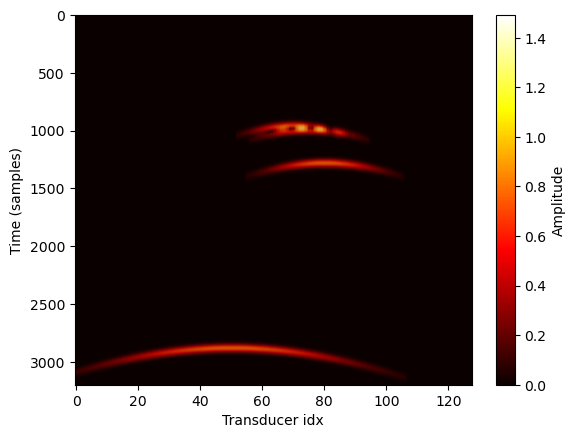

In [401]:
plt.imshow(abs(rf_matrix_zm_summed), cmap='hot', aspect='auto')
plt.xlabel("Transducer idx")
plt.ylabel("Time (samples)")
plt.colorbar(label="Amplitude")
plt.show()

### DC1

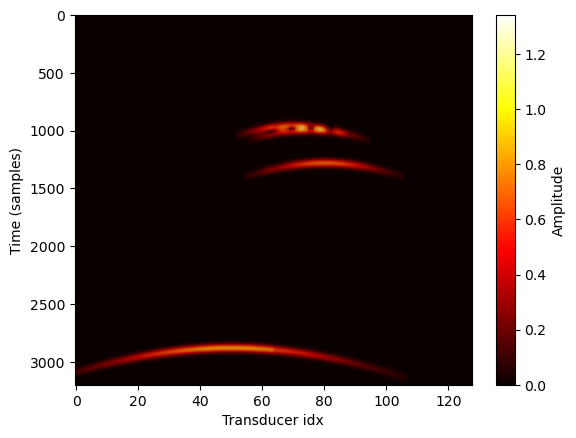

In [402]:
plt.imshow(abs(rf_matrix_dc1_summed), cmap='hot', aspect='auto')
plt.xlabel("Transducer idx")
plt.ylabel("Time (samples)")
plt.colorbar(label="Amplitude")
plt.show()

### DC2

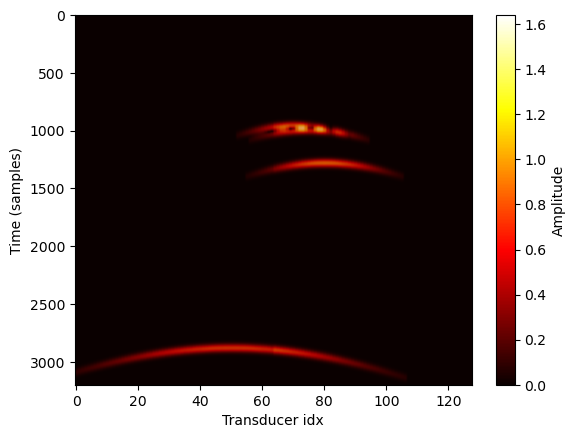

In [403]:
plt.imshow(abs(rf_matrix_dc2_summed), cmap='hot', aspect='auto')
plt.xlabel("Transducer idx")
plt.ylabel("Time (samples)")
plt.colorbar(label="Amplitude")
plt.show()

In [404]:
similarity_arr = rf_matrix_dc1_summed == rf_matrix_dc2_summed
similarity = np.sum(similarity_arr) / similarity_arr.size
print(f"Similarity between DC1 and DC2: {similarity*100}%")

Similarity between DC1 and DC2: 44.573974609375%


In [405]:
similarity_arr = rf_matrix_dc1_summed == rf_matrix_zm_summed
similarity = np.sum(similarity_arr) / similarity_arr.size
print(f"Similarity between DC1 and ZM: {similarity*100}%")

Similarity between DC1 and ZM: 44.603271484375%


In [406]:
similarity_arr = rf_matrix_dc2_summed == rf_matrix_zm_summed
similarity = np.sum(similarity_arr) / similarity_arr.size
print(f"Similarity between DC2 and ZM: {similarity*100}%")

Similarity between DC2 and ZM: 44.573974609375%


## Beamforming

In [407]:
@njit(parallel=True)
def beamforming_opt(rf_matrix_summed, lateral_resolution, samples, total_depth_sample, pitch, c, array_length, sampling_rate):
    bf_matrix = np.zeros((samples, lateral_resolution))

    for j in range(0, lateral_resolution):

        for k in range(0, samples):

            depth = total_depth_sample*k
            position = (pitch * array_length) * (j / lateral_resolution) #pitch isnt the same as the distance between transducers
            # we normalize the index to the total array length

            for l in range(0, array_length):

                delay = (depth / c) + np.sqrt(depth**2 + (l * pitch - position)**2) / c
                delay_idx = int(delay * sampling_rate) #delay in s * sampling rate in 1/s = delay in samples (number of samples to reach delay)

                if delay_idx < samples:
                    bf_matrix[k,j] += rf_matrix_summed[delay_idx, l] #we take sample in calculated rf_matrix (faster than recalculating)
    print("Beamforming done")
    return bf_matrix

In [408]:
bf_matrix_zm = beamforming_opt(rf_matrix_zm_summed, params["simulation"]["lateral_resolution"], params["simulation"]["samples"], params["simulation"]["total_depth_sample"], params["array"]["pitch"], params["wave"]["c"], params["array"]["length"], params["wave"]["sampling_rate"])

Beamforming done


In [409]:
bf_matrix_dc1 = beamforming_opt(rf_matrix_dc1_summed, params["simulation"]["lateral_resolution"], params["simulation"]["samples"], params["simulation"]["total_depth_sample"], params["array"]["pitch"], params["wave"]["c"], params["array"]["length"], params["wave"]["sampling_rate"])

Beamforming done


In [410]:
bf_matrix_dc2 = beamforming_opt(rf_matrix_dc2_summed, params["simulation"]["lateral_resolution"], params["simulation"]["samples"], params["simulation"]["total_depth_sample"], params["array"]["pitch"], params["wave"]["c"], params["array"]["length"], params["wave"]["sampling_rate"])

Beamforming done


## Display beamformed image

### ZM

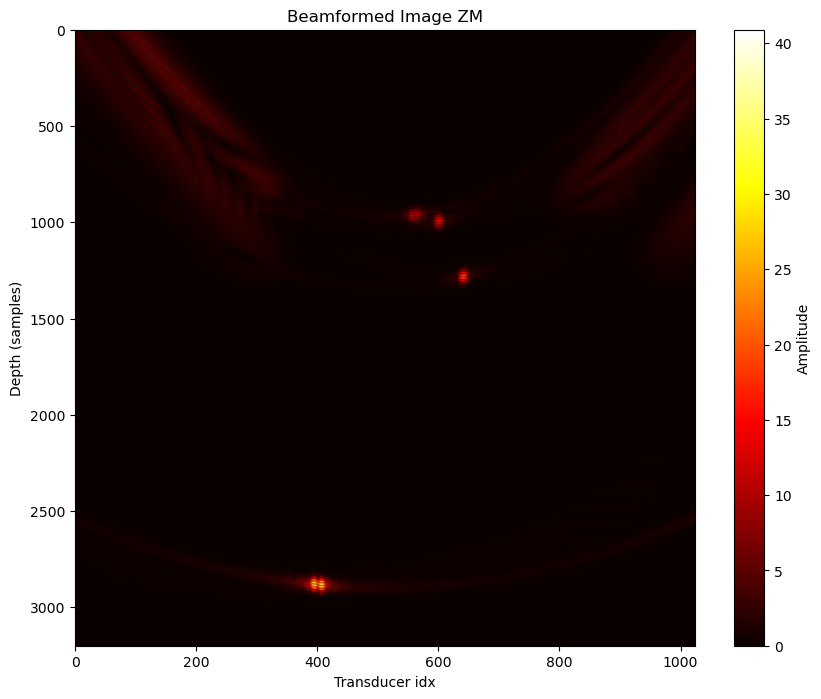

In [411]:
bf_matrix_zm.tofile(f"./data_nsi/csv/beamformed/bf_matrix_zm.csv", sep=",")
plt.figure(figsize=(10, 8))
plt.imshow(np.abs(bf_matrix_zm), cmap='hot', aspect='auto')
plt.title("Beamformed Image ZM")
plt.xlabel("Transducer idx")
plt.ylabel("Depth (samples)")
plt.colorbar(label="Amplitude")
plt.savefig("./data_nsi/images/bf_image_zm.png")
plt.show()

### DC1

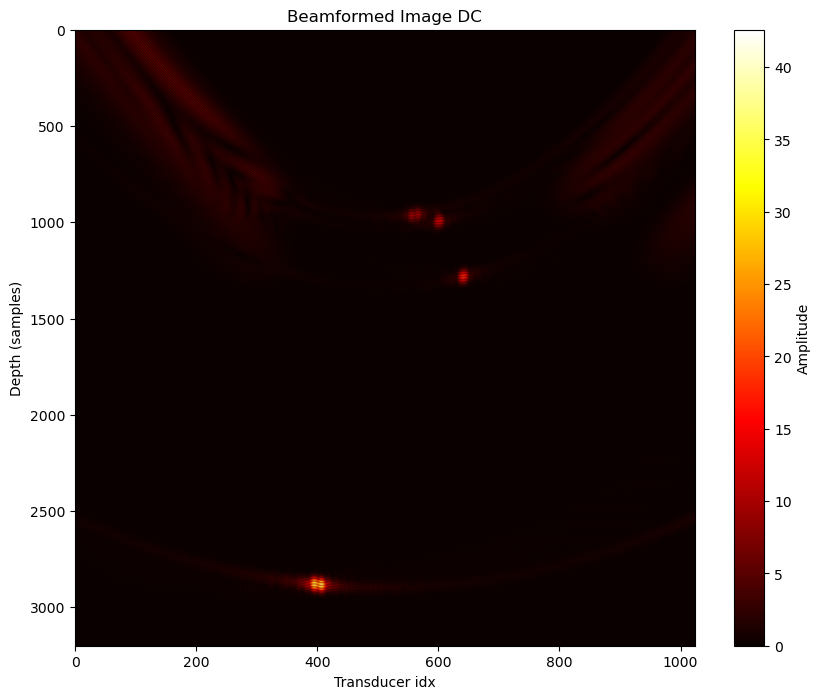

In [412]:
bf_matrix_dc1.tofile(f"./data_nsi/csv/beamformed/bf_matrix_dc1.csv", sep=",")
plt.figure(figsize=(10, 8))
plt.imshow(np.abs(bf_matrix_dc1), cmap='hot', aspect='auto')
plt.title("Beamformed Image DC")
plt.xlabel("Transducer idx")
plt.ylabel("Depth (samples)")
plt.colorbar(label="Amplitude")
plt.savefig("./data_nsi/images/bf_image_dc1.png")
plt.show()

### DC2

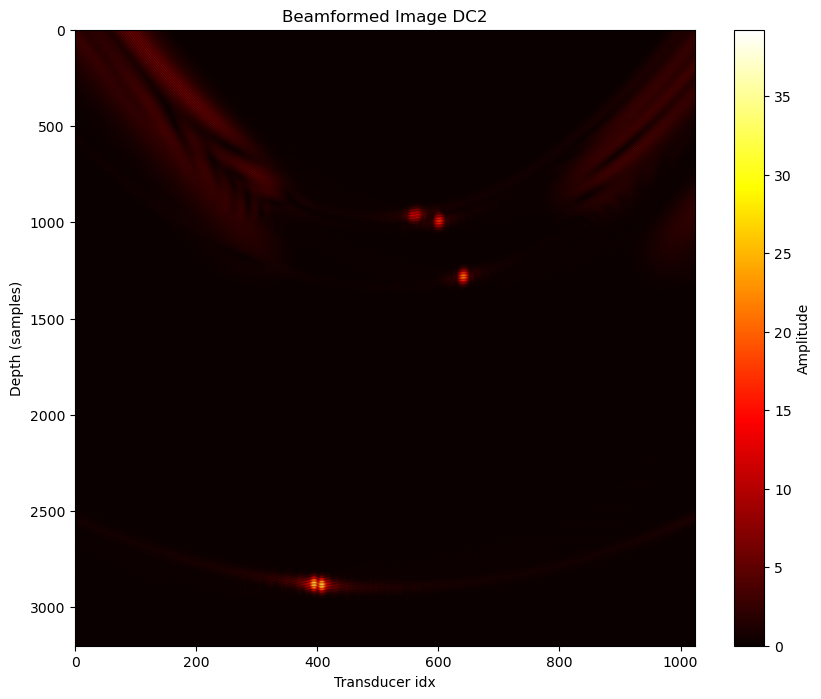

In [413]:
bf_matrix_dc2.tofile(f"./data_nsi/csv/beamformed/bf_matrix_dc2.csv", sep=",")
plt.figure(figsize=(10, 8))
plt.imshow(np.abs(bf_matrix_dc2), cmap='hot', aspect='auto')
plt.title("Beamformed Image DC2")
plt.xlabel("Transducer idx")
plt.ylabel("Depth (samples)")
plt.colorbar(label="Amplitude")
plt.savefig("./data_nsi/images/bf_image_dc2.png")
plt.show()

## Envelopes

In [414]:
env_zm = envelope(bf_matrix_zm, residual=None)
env_dc1 = envelope(bf_matrix_dc1, residual=None)
env_dc2 = envelope(bf_matrix_dc2, residual=None)

## Average offsets

In [415]:
similarity_arr = bf_matrix_dc1 == bf_matrix_dc2
similarity = np.sum(similarity_arr) / similarity_arr.size
print(f"Similarity between DC1 and DC2: {similarity*100}%")

similarity_arr = bf_matrix_zm == bf_matrix_dc1
similarity = np.sum(similarity_arr) / similarity_arr.size
print(f"Similarity between ZM and DC1: {similarity*100}%")

Similarity between DC1 and DC2: 0.066375732421875%
Similarity between ZM and DC1: 0.066375732421875%


In [416]:
env_nsi = (env_dc1 + env_dc2) / 2 - env_zm
env_nsi.tofile(f"./data_nsi/csv/beamformed/env_nsi.csv", sep=",")

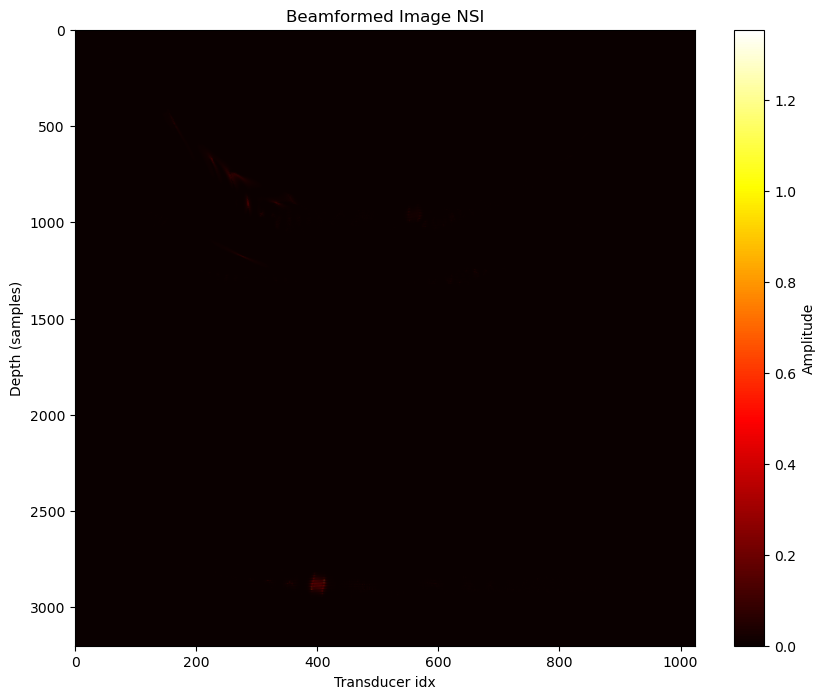

In [417]:
plt.figure(figsize=(10, 8))
plt.imshow(np.abs(env_nsi), cmap='hot', aspect='auto')
plt.title("Beamformed Image NSI")
plt.xlabel("Transducer idx")
plt.ylabel("Depth (samples)")
plt.colorbar(label="Amplitude")
plt.show()

In [418]:
db_nsi = 20 * np.log10(np.abs(env_nsi) - np.max(np.abs(env_nsi)))
db_nsi.tofile(f"./data_nsi/csv/beamformed/env_nsi_db.csv", sep=",")

C:\Users\Acer\AppData\Local\Temp\ipykernel_10096\3054766621.py:1: RuntimeWarning: divide by zero encountered in log10
  db_nsi = 20 * np.log10(np.abs(env_nsi) - np.max(np.abs(env_nsi)))
C:\Users\Acer\AppData\Local\Temp\ipykernel_10096\3054766621.py:1: RuntimeWarning: invalid value encountered in log10
  db_nsi = 20 * np.log10(np.abs(env_nsi) - np.max(np.abs(env_nsi)))


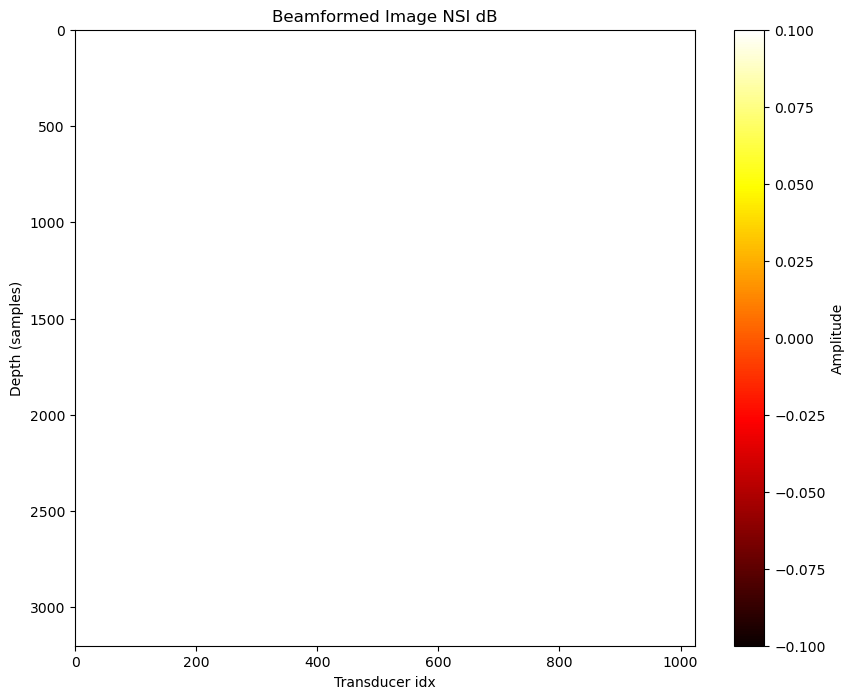

In [419]:
plt.figure(figsize=(10, 8))
plt.imshow(np.abs(db_nsi), cmap='hot', aspect='auto')
plt.title("Beamformed Image NSI dB")
plt.xlabel("Transducer idx")
plt.ylabel("Depth (samples)")
plt.colorbar(label="Amplitude")
plt.show()